In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('iqsize.csv')
print(df)

/Users/hyeongjin/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


    PIQ   Brain  Height  Weight
0   124   81.69    64.5     118
1   150  103.84    73.3     143
2   128   96.54    68.8     172
3   134   95.15    65.0     147
4   110   92.88    69.0     146
5   131   99.13    64.5     138
6    98   85.43    66.0     175
7    84   90.49    66.3     134
8   147   95.55    68.8     172
9   124   83.39    64.5     118
10  128  107.95    70.0     151
11  124   92.41    69.0     155
12  147   85.65    70.5     155
13   90   87.89    66.0     146
14   96   86.54    68.0     135
15  120   85.22    68.5     127
16  102   94.51    73.5     178
17   84   80.80    66.3     136
18   86   88.91    70.0     180
19   84   90.59    76.5     186
20  134   79.06    62.0     122
21  128   95.50    68.0     132
22  102   83.18    63.0     114
23  131   93.55    72.0     171
24   84   79.86    68.0     140
25  110  106.25    77.0     187
26   72   79.35    63.0     106
27  124   86.67    66.5     159
28  132   85.78    62.5     127
29  137   94.96    67.0     191
30  110 

In [2]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.stats.anova import anova_lm

# Linear Regression y~x
model = smf.ols('PIQ ~ Brain + Height + Weight', data=df).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    PIQ   R-squared:                       0.295
Model:                            OLS   Adj. R-squared:                  0.233
Method:                 Least Squares   F-statistic:                     4.741
Date:                Mon, 12 Oct 2026   Prob (F-statistic):            0.00722
Time:                        22:34:17   Log-Likelihood:                -165.25
No. Observations:                  38   AIC:                             338.5
Df Residuals:                      34   BIC:                             345.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    111.3536     62.971      1.768      0.086     -16.619     239.326
Brain          2.0604      0.563      3.657      0.001       0.915       3.205
Height        -2.7319      1.229     -2.222      0.033      -5.230      -0.233
Weight         0.0006      0.197      0.003      0.998      -0.400       0.401
==============================================================================
Omnibus:                        1.379   Durbin-Watson:                   1.827
Prob(Omnibus):                  0.502   Jarque-Bera (JB):                1.088
Skew:                           0.409   Prob(JB):                        0.580
Kurtosis:                       2.859   Cond. No.                     3.73e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.73e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

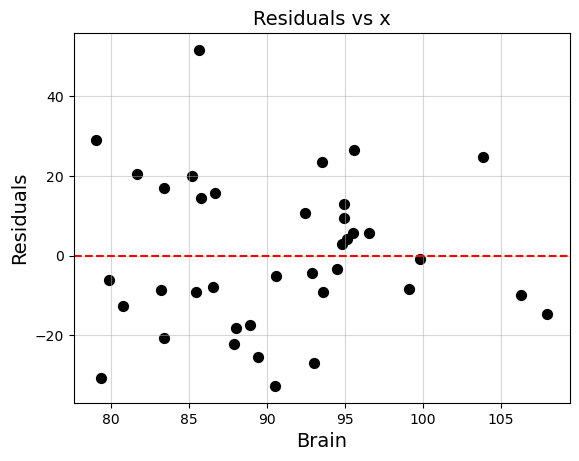

In [3]:
# Residuals vs x
plt.scatter(df['Brain'], model.resid, color='black', s=50)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Brain', fontsize=14)
plt.ylabel('Residuals', fontsize=14)
plt.title('Residuals vs x', fontsize=14)
plt.grid(True, alpha=0.5)

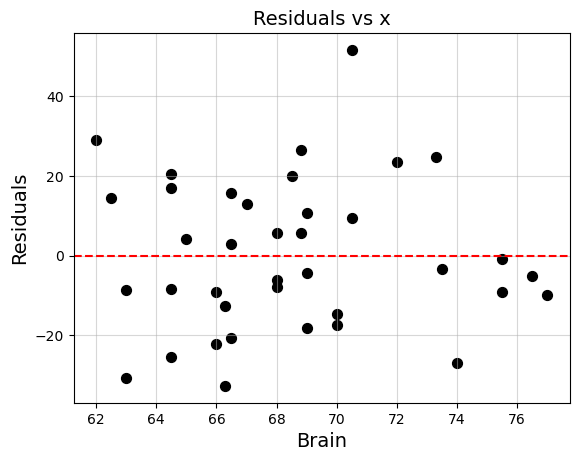

In [4]:
# Residuals vs x
plt.scatter(df['Height'], model.resid, color='black', s=50)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Brain', fontsize=14)
plt.ylabel('Residuals', fontsize=14)
plt.title('Residuals vs x', fontsize=14)
plt.grid(True, alpha=0.5)

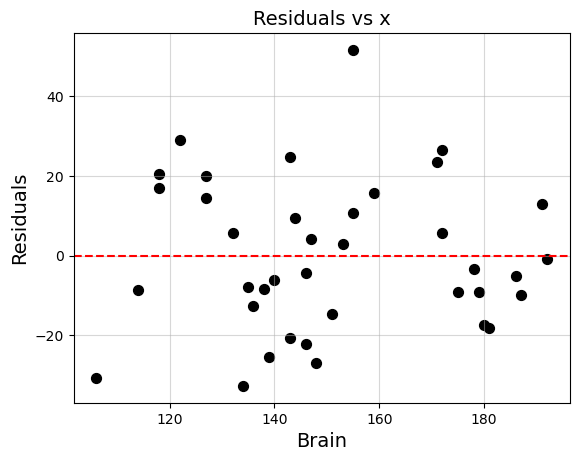

In [5]:
# Residuals vs x
plt.scatter(df['Weight'], model.resid, color='black', s=50)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Brain', fontsize=14)
plt.ylabel('Residuals', fontsize=14)
plt.title('Residuals vs x', fontsize=14)
plt.grid(True, alpha=0.5)

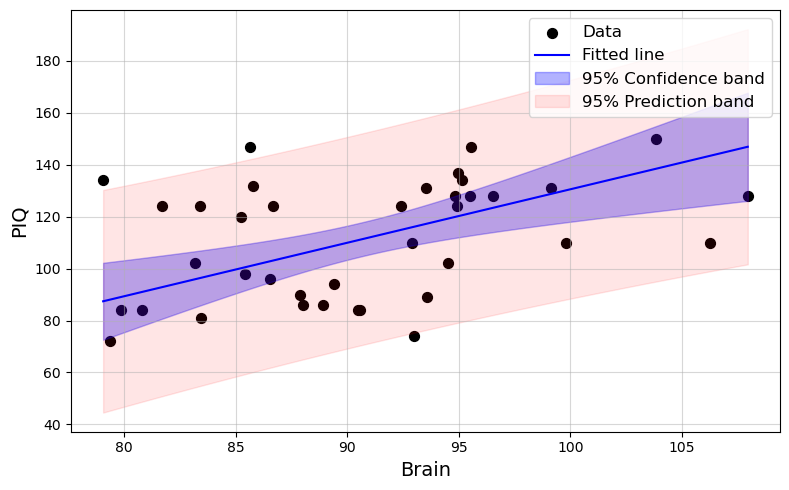

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Multiple linear regression
model = smf.ols('PIQ ~ Brain + Height + Weight', data=df).fit()

# Vary Brain over its observed range; hold Height and Weight at their means
brain_grid = np.linspace(df['Brain'].min(), df['Brain'].max(), 100)
new_df = pd.DataFrame({
    'Brain': brain_grid,
    'Height': df['Height'].mean(),
    'Weight': df['Weight'].mean(),
})

# Fitted values, confidence band (mean response), prediction band (new observation)
pred = model.get_prediction(new_df).summary_frame(alpha=0.05)

plt.figure(figsize=(8, 5))
plt.scatter(df['Brain'], df['PIQ'], color='black', s=50, label='Data')
plt.plot(brain_grid, pred['mean'], color='blue', label='Fitted line')

# Confidence band (CI for the mean response)
plt.fill_between(brain_grid, pred['mean_ci_lower'], pred['mean_ci_upper'],
                 alpha=0.3, color='blue', label='95% Confidence band')

# Prediction band (interval for an individual new observation)
plt.fill_between(brain_grid, pred['obs_ci_lower'], pred['obs_ci_upper'],
                 alpha=0.1, color='red', label='95% Prediction band')

plt.xlabel('Brain', fontsize=14)
plt.ylabel('PIQ', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()